# 05. Baseline e regressão — dias de atraso por contrato

**Objetivo:** estimar `target_dias_atraso` (quantos dias a obra passou do prazo vigente) para os 48 contratos selecionados.

## Definição do alvo

1. `fim_original = data_ordem_servico + prazo_total`
2. **Ajuste por aditivos de prazo:** `fim_ajustado` = maior `Data_termino_nova` entre os aditivos do contrato (ou `fim_original`, se não houver aditivo). Na prática, é o fim original acrescido dos dias aditados.
3. `duracao_real_dias = data_recebimento_provisorio - data_ordem_servico` (tempo que a obra levou para terminar)
4. `prazo_ajustado_dias = fim_ajustado - data_ordem_servico`
5. `atraso_bruto_dias = duracao_real_dias - prazo_ajustado_dias` (negativo = terminou antes do prazo vigente)
6. `target_dias_atraso = max(0, atraso_bruto_dias)`

## Modelos

- **Baseline:** mediana do atraso no conjunto de treino (`DummyRegressor`).
- **Regressão:** Random Forest regularizado, usando só informações conhecidas na ordem de serviço (sem aditivos, execução ou liberações, que só existem durante/depois da obra).

## Validação

Mesma lógica do 04B: contratos ordenados por `data_recebimento_provisorio`; os 8 mais recentes ficam como teste final; os 40 anteriores formam 4 janelas expanding (20→5, 25→5, 30→5, 35→5).

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
N_TEST = 8
MIN_TRAIN = 20
BLOCK = 5
N_FOLDS = 4

# Se os CSVs estiverem em outra pasta, defina DATA_DIR manualmente.
DATA_DIR = None

## 1. Carga dos dados

In [2]:
FILES = {
    "contratos": "vw_modelagem_contratos_filtros.csv",
    "aditivos_prazo": "vw_taditivoprazo.csv",
    "aditivos_valor": "vw_taditivovalor.csv",
    "liberacoes": "vw_tparcela_liberacao.csv",
    "parcelas": "vw_bi_parcelas.csv",
}


def find_data_dir():
    if DATA_DIR is not None:
        return Path(DATA_DIR)

    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd / "data", cwd / "data" / "raw", cwd / "data" / "processed"]
    for parent in cwd.parents:
        candidates += [parent / "data", parent / "data" / "raw"]
    candidates.append(Path("/mnt/user-data/uploads"))

    for folder in candidates:
        if (folder / FILES["contratos"]).exists():
            return folder

    raise FileNotFoundError("CSVs não encontrados; defina DATA_DIR.")


base = find_data_dir()
print("Pasta de dados:", base)


def read(name, **kw):
    return pd.read_csv(base / FILES[name], encoding="utf-8-sig", **kw)


contratos = read(
    "contratos",
    parse_dates=["data_assinatura", "data_ordem_servico", "data_recebimento_provisorio"],
)
aditivos_prazo = read(
    "aditivos_prazo",
    parse_dates=["Data_termino_anterior", "Data_termino_nova", "Data_assinatura_ta_prazo"],
)
parcelas = read("parcelas")

print("contratos:", contratos.shape, "| únicos:", contratos["idContrato"].nunique())
print("aditivos de prazo (todos):", aditivos_prazo.shape)
print("parcelas (todas):", parcelas.shape)

assert contratos["idContrato"].is_unique
assert contratos[["data_ordem_servico", "data_recebimento_provisorio", "prazo_total"]].notna().all().all()

Pasta de dados: /home/claude/work
contratos: (48, 50) | únicos: 48
aditivos de prazo (todos): (245, 10)
parcelas (todas): (13010, 11)


## 2. Construção do alvo com ajuste por aditivos de prazo

As tabelas de aditivos cobrem mais contratos do que a seleção; o filtro é feito por `idContrato`.

In [3]:
c = contratos.copy()

c["fim_original"] = c["data_ordem_servico"] + pd.to_timedelta(c["prazo_total"], unit="D")

adit = aditivos_prazo[aditivos_prazo["idContrato"].isin(c["idContrato"])].copy()

adit_resumo = (
    adit.groupby("idContrato")
    .agg(
        qtd_aditivos_prazo=("Aditado_em_dias", "size"),
        dias_aditados_soma=("Aditado_em_dias", "sum"),
        primeiro_termino_anterior=("Data_termino_anterior", "min"),
        data_termino_aditada=("Data_termino_nova", "max"),
    )
    .reset_index()
)

c = c.merge(adit_resumo, on="idContrato", how="left")
c[["qtd_aditivos_prazo", "dias_aditados_soma"]] = c[["qtd_aditivos_prazo", "dias_aditados_soma"]].fillna(0)

# Fim vigente = maior data de término nova; sem aditivo, vale o fim original.
c["fim_ajustado"] = c[["fim_original", "data_termino_aditada"]].max(axis=1)
c["dias_aditados_efetivos"] = (c["fim_ajustado"] - c["fim_original"]).dt.days
c["prazo_ajustado_dias"] = c["prazo_total"] + c["dias_aditados_efetivos"]

c["duracao_real_dias"] = (c["data_recebimento_provisorio"] - c["data_ordem_servico"]).dt.days
c["atraso_bruto_dias"] = c["duracao_real_dias"] - c["prazo_ajustado_dias"]

c["target_dias_atraso"] = c["atraso_bruto_dias"].clip(lower=0)
c["target_atraso"] = (c["target_dias_atraso"] > 0).astype(int)

print("Contratos com aditivo de prazo:", int((c["qtd_aditivos_prazo"] > 0).sum()), "de", len(c))
print("Status dos aditivos considerados:", adit["Status_aditivo_prazo"].value_counts().to_dict())

Contratos com aditivo de prazo: 37 de 48
Status dos aditivos considerados: {'CONCLUÍDO': 84, 'ASSINADO': 1}


### Verificações do ajuste

- O primeiro `Data_termino_anterior` de cada contrato deve coincidir com `data_ordem_servico + prazo_total`. Se coincide, a ancoragem das datas está correta.
- A soma de `Aditado_em_dias` deve coincidir com a extensão efetiva do prazo. Divergências indicam aditivos sobrepostos.

In [4]:
com_adit = c[c["qtd_aditivos_prazo"] > 0].copy()

ancora_ok = (com_adit["primeiro_termino_anterior"] == com_adit["fim_original"])
print(f"Primeiro término anterior == OS + prazo_total: {int(ancora_ok.sum())}/{len(com_adit)} contratos")

diverge = com_adit[com_adit["dias_aditados_soma"] != com_adit["dias_aditados_efetivos"]]
print(f"Contratos em que soma dos dias != extensão efetiva: {len(diverge)}")
display(diverge[["idContrato", "NumeroContrato", "qtd_aditivos_prazo", "dias_aditados_soma", "dias_aditados_efetivos"]])

display(
    adit[adit["idContrato"].isin(diverge["idContrato"])]
    .sort_values(["idContrato", "Data_termino_nova"])
    [["idContrato", "Data_termino_anterior", "Data_termino_nova", "Aditado_em_dias", "Status_aditivo_prazo"]]
)

Primeiro término anterior == OS + prazo_total: 37/37 contratos
Contratos em que soma dos dias != extensão efetiva: 1


,idContrato,NumeroContrato,qtd_aditivos_prazo,dias_aditados_soma,dias_aditados_efetivos
5,31,111/2019,2.000,90.000,60


,idContrato,Data_termino_anterior,Data_termino_nova,Aditado_em_dias,Status_aditivo_prazo
6,31,2019-11-08,2019-12-08,30,CONCLUÍDO
7,31,2019-11-08,2020-01-07,60,CONCLUÍDO


Nos contratos divergentes (hoje, apenas o 111/2019) há aditivos que partem do mesmo `Data_termino_anterior` (sobrepostos): somar os dias contaria a extensão duas vezes. Por isso o fim ajustado usa a **maior `Data_termino_nova`**, que é o término de fato vigente.

## 3. Distribuição do alvo

,contratos,com_atraso,taxa_atraso,media_dias,mediana_dias,max_dias,terminou_antes
0,48,17,0.354,31.104,0.000,380,11


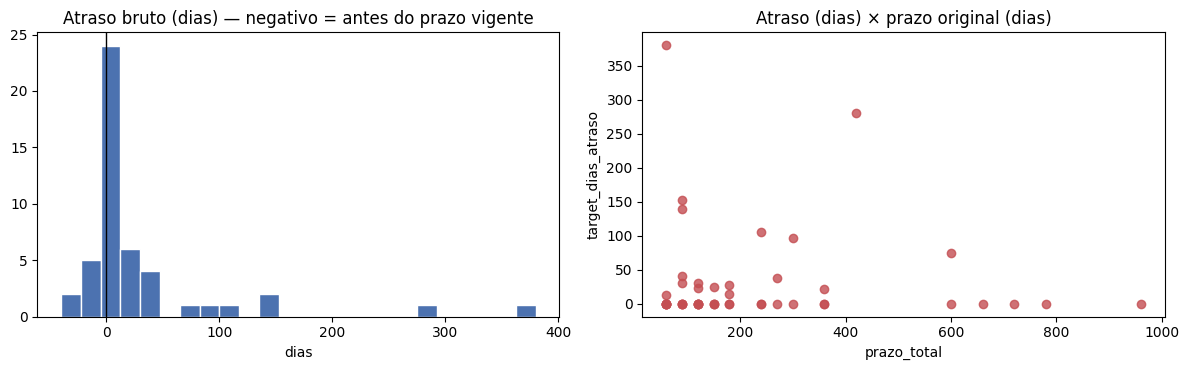

In [5]:
resumo_alvo = pd.DataFrame({
    "contratos": [len(c)],
    "com_atraso": [int(c["target_atraso"].sum())],
    "taxa_atraso": [c["target_atraso"].mean()],
    "media_dias": [c["target_dias_atraso"].mean()],
    "mediana_dias": [c["target_dias_atraso"].median()],
    "max_dias": [c["target_dias_atraso"].max()],
    "terminou_antes": [int((c["atraso_bruto_dias"] < 0).sum())],
})
display(resumo_alvo)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(c["atraso_bruto_dias"], bins=24, color="#4C72B0", edgecolor="white")
axes[0].axvline(0, color="k", lw=1)
axes[0].set_title("Atraso bruto (dias) — negativo = antes do prazo vigente")
axes[0].set_xlabel("dias")

axes[1].scatter(c["prazo_total"], c["target_dias_atraso"], c="#C44E52", alpha=0.8)
axes[1].set_title("Atraso (dias) × prazo original (dias)")
axes[1].set_xlabel("prazo_total")
axes[1].set_ylabel("target_dias_atraso")

plt.tight_layout()
plt.show()

O alvo é **inflado em zeros**: a maior parte dos contratos termina dentro do prazo vigente e poucos concentram atrasos grandes. Isso pesa na escolha do baseline (a mediana tende a ser 0) e na leitura do MAE.

## 4. Features (conhecidas na ordem de serviço)

Entram apenas informações disponíveis no início da obra. Ficam de fora, por vazamento: aditivos de prazo e de valor, datas efetivas das parcelas, liberações e qualquer coisa derivada da execução. As datas previstas das parcelas também ficam de fora, pois são reescritas quando há aditivo.

- Contrato: `prazo_total`, `log_valor_total`, `log_valor_por_dia`, `perc_desconto`, `licitado`, `dias_assinatura_ate_os`
- Plano: `n_parcelas_originais` (parcelas de "Serviços Originais")
- Histórico: `fornecedor_contratos_anteriores`, `predio_contratos_anteriores` (contratos da seleção com OS anterior)
- Categóricas: `Classificacao_contrato`, `id_setor_divisao`

In [6]:
n_parcelas = (
    parcelas[parcelas["tipo_de_parcela"].eq("Serviços Originais")]
    .groupby("id_contrato")["id_parcela"]
    .nunique()
    .rename("n_parcelas_originais")
)

c = c.merge(n_parcelas, left_on="idContrato", right_index=True, how="left")

c["log_valor_total"] = np.log(c["valor_total_contrato"])
c["log_valor_por_dia"] = np.log(c["valor_total_contrato"] / c["prazo_total"])
c["perc_desconto"] = c["Perc_desconto"]
c["licitado"] = (c["Valor_licitado"] > 0).astype(int)
c["dias_assinatura_ate_os"] = (c["data_ordem_servico"] - c["data_assinatura"]).dt.days

c = c.sort_values(["data_ordem_servico", "idContrato"]).reset_index(drop=True)
c["fornecedor_contratos_anteriores"] = c.groupby("id_fornecedor").cumcount()
c["predio_contratos_anteriores"] = c.groupby("id_predio").cumcount()

NUMERIC_FEATURES = [
    "prazo_total",
    "log_valor_total",
    "log_valor_por_dia",
    "perc_desconto",
    "licitado",
    "dias_assinatura_ate_os",
    "n_parcelas_originais",
    "fornecedor_contratos_anteriores",
    "predio_contratos_anteriores",
]
CATEGORICAL_FEATURES = ["Classificacao_contrato", "id_setor_divisao"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("Faltantes por feature:")
print(c[FEATURES].isna().sum()[lambda s: s > 0].to_dict() or "nenhum")
display(c[NUMERIC_FEATURES].describe().T)

Faltantes por feature:
{'n_parcelas_originais': 1}


,count,mean,std,min,25%,50%,75%,max
prazo_total,48.000,230.000,213.512,60.000,90.000,150.000,277.500,960.000
log_valor_total,48.000,13.605,1.495,11.218,12.643,13.390,14.369,16.801
log_valor_por_dia,48.000,8.496,0.899,6.503,7.946,8.352,9.188,10.261
perc_desconto,48.000,3.458,7.133,0.000,0.000,0.000,4.067,31.660
licitado,48.000,0.417,0.498,0.000,0.000,0.000,1.000,1.000
dias_assinatura_ate_os,48.000,56.438,56.572,9.000,27.500,40.000,54.750,267.000
n_parcelas_originais,47.000,8.809,8.208,1.000,3.000,5.000,12.000,32.000
fornecedor_contratos_anteriores,48.000,0.625,1.044,0.000,0.000,0.000,1.000,4.000
predio_contratos_anteriores,48.000,0.250,0.526,0.000,0.000,0.000,0.000,2.000


## 5. Separação desenvolvimento × teste final e janelas temporais

In [7]:
c = c.sort_values(["data_recebimento_provisorio", "idContrato"]).reset_index(drop=True)

dev = c.iloc[:-N_TEST].copy()
test = c.iloc[-N_TEST:].copy()

assert len(dev) == 40 and len(test) == 8
assert dev["data_recebimento_provisorio"].max() <= test["data_recebimento_provisorio"].min()

print("Teste final:", test["idContrato"].tolist())

folds = []
for k in range(N_FOLDS):
    n_train = MIN_TRAIN + k * BLOCK
    folds.append({
        "fold": k + 1,
        "train": dev.iloc[:n_train],
        "val": dev.iloc[n_train:n_train + BLOCK],
    })

display(pd.DataFrame([
    {
        "fold": f["fold"],
        "contratos_treino": len(f["train"]),
        "contratos_validacao": len(f["val"]),
        "fim_validacao_min": f["val"]["data_recebimento_provisorio"].min().date(),
        "fim_validacao_max": f["val"]["data_recebimento_provisorio"].max().date(),
        "atraso_medio_treino": f["train"]["target_dias_atraso"].mean(),
        "mediana_treino": f["train"]["target_dias_atraso"].median(),
        "atraso_medio_validacao": f["val"]["target_dias_atraso"].mean(),
        "com_atraso_validacao": int(f["val"]["target_atraso"].sum()),
    }
    for f in folds
]))

Teste final: [173, 201, 287, 283, 342, 317, 254, 377]


,fold,contratos_treino,contratos_validacao,fim_validacao_min,fim_validacao_max,atraso_medio_treino,mediana_treino,atraso_medio_validacao,com_atraso_validacao
0,1,20,5,2021-05-27,2023-07-09,38.000,0.000,30.000,3
1,2,25,5,2023-07-10,2024-04-23,36.400,0.000,63.800,2
2,3,30,5,2024-05-06,2024-09-02,40.967,0.000,0.000,0
3,4,35,5,2024-09-05,2025-03-17,35.114,0.000,17.800,2


**Limitação conhecida:** a ordenação é pelo fim da obra, mas as obras duram até ~3 anos. Um contrato de validação pode ter começado antes de algum contrato de treino terminar. Isso torna a validação levemente otimista, e é o mesmo critério do 04B.

## 6. Baseline, modelo e métricas

- **Baseline:** mediana do atraso no treino.
- **Regressão:** Random Forest com árvores rasas (`max_depth=3`, `min_samples_leaf=3`), porque são só 20 a 40 contratos por treino.
- Previsões negativas são truncadas em zero.

In [8]:
def preprocessing():
    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ]
    )


def make_baseline():
    return DummyRegressor(strategy="median")


def make_regressor():
    return Pipeline([
        ("prep", preprocessing()),
        ("model", RandomForestRegressor(
            n_estimators=500,
            max_depth=3,
            min_samples_leaf=3,
            max_features=0.5,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])


def predict(model, frame):
    return np.maximum(0, model.predict(frame[FEATURES]))


def metrics(y_true, y_pred, full=False):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.maximum(0, np.asarray(y_pred, dtype=float))
    atrasados = y_true > 0

    out = {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "mae_so_atrasados": mean_absolute_error(y_true[atrasados], y_pred[atrasados]) if atrasados.any() else np.nan,
        "vies_medio": (y_pred - y_true).mean(),
    }

    if full:
        out["r2"] = r2_score(y_true, y_pred)
        out["spearman"] = spearmanr(y_true, y_pred)[0] if np.unique(y_pred).size > 1 else np.nan

    return out

## 7. Validação temporal (somente desenvolvimento)

In [9]:
cv_rows = []
oof_rows = []

for f in folds:
    tr, va = f["train"], f["val"]

    baseline = make_baseline().fit(tr[FEATURES], tr["target_dias_atraso"])
    regressor = make_regressor().fit(tr[FEATURES], tr["target_dias_atraso"])

    preds = {
        "baseline_mediana": predict(baseline, va),
        "random_forest": predict(regressor, va),
    }

    for name, pred in preds.items():
        cv_rows.append({"fold": f["fold"], "modelo": name, **metrics(va["target_dias_atraso"], pred)})

    oof_rows.append(pd.DataFrame({
        "fold": f["fold"],
        "id_contrato": va["idContrato"].values,
        "prazo_total": va["prazo_total"].values,
        "real": va["target_dias_atraso"].values,
        "baseline_mediana": preds["baseline_mediana"],
        "random_forest": preds["random_forest"],
    }))

cv = pd.DataFrame(cv_rows)
oof = pd.concat(oof_rows, ignore_index=True)

print("Métricas por janela:")
display(cv.pivot(index="fold", columns="modelo", values="mae").rename_axis(columns="MAE"))

cv_resumo = (
    cv.groupby("modelo")
    .agg(mae_medio=("mae", "mean"), mae_dp=("mae", "std"), rmse_medio=("rmse", "mean"))
    .sort_values("mae_medio")
)
print("Resumo entre janelas:")
display(cv_resumo)

pooled = pd.DataFrame({
    name: metrics(oof["real"], oof[name], full=True)
    for name in ["baseline_mediana", "random_forest"]
}).T
print("Métricas agregadas (20 contratos de validação, previsões out-of-fold):")
display(pooled)

Métricas por janela:


MAE,baseline_mediana,random_forest
fold,,
1,30.000,55.133
2,63.800,69.098
3,0.000,36.363
4,17.800,19.151


Resumo entre janelas:


,mae_medio,mae_dp,rmse_medio
modelo,,,
baseline_mediana,27.900,26.917,52.053
random_forest,44.936,21.803,59.487


Métricas agregadas (20 contratos de validação, previsões out-of-fold):


,mae,rmse,mae_so_atrasados,vies_medio,r2,spearman
baseline_mediana,27.900,69.787,79.714,-27.900,-0.190,NaN
random_forest,44.936,68.548,57.671,6.853,-0.148,-0.138


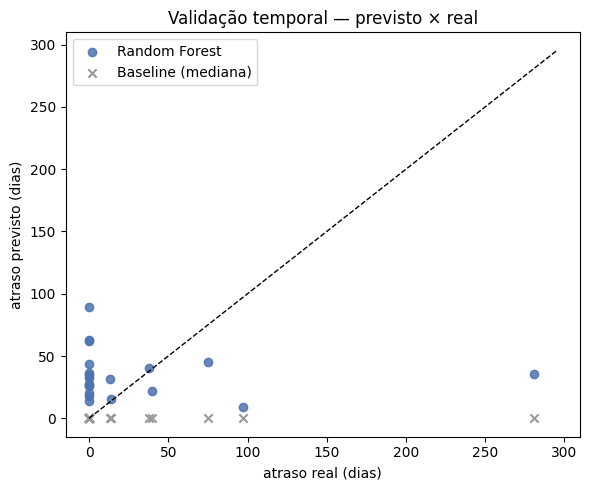

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(oof["real"], oof["random_forest"], c="#4C72B0", label="Random Forest", alpha=0.85)
ax.scatter(oof["real"], oof["baseline_mediana"], c="#999999", marker="x", label="Baseline (mediana)")

lim = max(oof["real"].max(), oof["random_forest"].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set_xlabel("atraso real (dias)")
ax.set_ylabel("atraso previsto (dias)")
ax.set_title("Validação temporal — previsto × real")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Teste final

In [11]:
baseline_final = make_baseline().fit(dev[FEATURES], dev["target_dias_atraso"])
regressor_final = make_regressor().fit(dev[FEATURES], dev["target_dias_atraso"])

test_pred = test[["idContrato", "prazo_total", "target_dias_atraso"]].rename(
    columns={"idContrato": "id_contrato", "target_dias_atraso": "real"}
).reset_index(drop=True)
test_pred["baseline_mediana"] = predict(baseline_final, test)
test_pred["random_forest"] = predict(regressor_final, test)

test_metrics = pd.DataFrame({
    name: metrics(test_pred["real"], test_pred[name], full=True)
    for name in ["baseline_mediana", "random_forest"]
}).T

print("Mediana usada no baseline:", baseline_final.constant_.ravel()[0])
display(test_metrics)
display(test_pred)

Mediana usada no baseline: 0.0


,mae,rmse,mae_so_atrasados,vies_medio,r2,spearman
baseline_mediana,21.875,54.352,87.500,-21.875,-0.193,NaN
random_forest,51.653,63.861,74.187,14.560,-0.647,-0.764


,id_contrato,prazo_total,real,baseline_mediana,random_forest
0,173,960,0,0.000,55.396
1,201,780,0,0.000,51.237
2,287,360,0,0.000,27.599
3,283,270,0,0.000,24.187
4,342,60,0,0.000,50.111
5,317,120,23,0.000,15.501
6,254,600,0,0.000,56.323
7,377,90,152,0.000,11.125


In [12]:
mae_b = test_metrics.loc["baseline_mediana", "mae"]
mae_m = test_metrics.loc["random_forest", "mae"]
cv_b = cv_resumo.loc["baseline_mediana", "mae_medio"]
cv_m = cv_resumo.loc["random_forest", "mae_medio"]

print(f"Validação temporal — MAE médio: baseline {cv_b:.1f} | RF {cv_m:.1f}")
print(f"Teste final       — MAE:        baseline {mae_b:.1f} | RF {mae_m:.1f}")
print()
print("O RF supera o baseline na validação temporal?", "SIM" if cv_m < cv_b else "NÃO")
print("O RF supera o baseline no teste final?", "SIM" if mae_m < mae_b else "NÃO")

Validação temporal — MAE médio: baseline 27.9 | RF 44.9
Teste final       — MAE:        baseline 21.9 | RF 51.7

O RF supera o baseline na validação temporal? NÃO
O RF supera o baseline no teste final? NÃO


## 9. Importância das features (modelo final)

,importancia
num__dias_assinatura_ate_os,0.215
num__log_valor_por_dia,0.206
num__log_valor_total,0.193
num__n_parcelas_originais,0.180
num__prazo_total,0.120
num__perc_desconto,0.050
num__fornecedor_contratos_anteriores,0.015
cat__Classificacao_contrato_Reforma Parcial e Ampliação,0.009
cat__Classificacao_contrato_Reforma Parcial,0.007
num__licitado,0.003


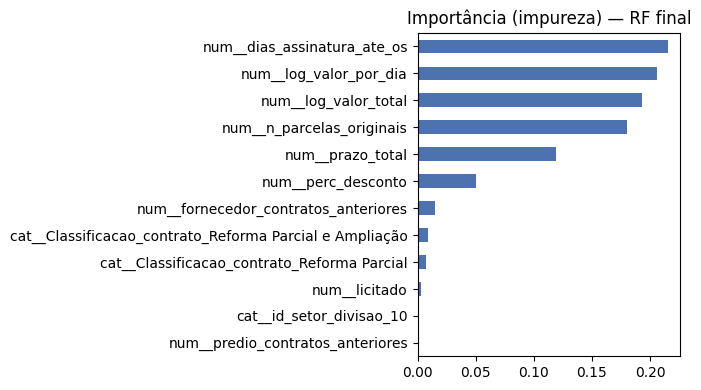

In [13]:
names = regressor_final["prep"].get_feature_names_out()
imp = pd.Series(regressor_final["model"].feature_importances_, index=names).sort_values(ascending=False)
display(imp.head(12).to_frame("importancia"))

imp.head(12).iloc[::-1].plot.barh(figsize=(7, 4), color="#4C72B0", title="Importância (impureza) — RF final")
plt.tight_layout()
plt.show()

## 10. Alternativas (opcional, só validação temporal)

Comparação rápida nas mesmas janelas, **sem tocar no teste final**. Serve para checar se o resultado do RF é específico do modelo.

In [14]:
def make_gbr_lad():
    return Pipeline([
        ("prep", preprocessing()),
        ("model", GradientBoostingRegressor(
            loss="absolute_error", n_estimators=100, learning_rate=0.05,
            max_depth=2, min_samples_leaf=3, subsample=0.8, random_state=RANDOM_STATE,
        )),
    ])


class RidgeLog:
    def __init__(self):
        self.pipe = Pipeline([
            ("prep", ColumnTransformer([
                ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUMERIC_FEATURES),
                ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
            ])),
            ("model", Ridge(alpha=10)),
        ])

    def fit(self, X, y):
        self.pipe.fit(X, np.log1p(y))
        return self

    def predict(self, X):
        return np.expm1(self.pipe.predict(X))


alternativas = {
    "GradientBoosting (L1)": make_gbr_lad,
    "Ridge (log1p)": RidgeLog,
}

alt_rows = []
for f in folds:
    tr, va = f["train"], f["val"]
    for name, factory in alternativas.items():
        m = factory().fit(tr[FEATURES], tr["target_dias_atraso"])
        alt_rows.append({"fold": f["fold"], "modelo": name, **metrics(va["target_dias_atraso"], predict(m, va))})

alt = pd.concat([cv, pd.DataFrame(alt_rows)], ignore_index=True)
display(
    alt.groupby("modelo")
    .agg(mae_medio=("mae", "mean"), mae_dp=("mae", "std"), rmse_medio=("rmse", "mean"))
    .sort_values("mae_medio")
)

,mae_medio,mae_dp,rmse_medio
modelo,,,
baseline_mediana,27.900,26.917,52.053
GradientBoosting (L1),29.517,25.120,50.904
Ridge (log1p),40.943,44.292,58.945
random_forest,44.936,21.803,59.487


## Leitura dos resultados

**O Random Forest não supera o baseline.** Com os dados e features atuais, prever "sem atraso" (mediana = 0) é melhor do que o modelo.

| | MAE validação temporal (média de 4 janelas) | MAE teste final (8 contratos) |
|---|---|---|
| Baseline (mediana = 0 dia) | 27,9 | 21,9 |
| Random Forest | 44,9 | 51,7 |

- **Por que o baseline é forte:** 31 dos 48 contratos têm atraso zero (mediana 0). Como o MAE premia a mediana, prever 0 já acerta a maioria. O RF prevê entre ~11 e ~56 dias para quase todos os contratos e erra feio nos que terminaram no prazo.
- **O RF também não ordena bem:** Spearman de −0,14 na validação e −0,76 no teste, ou seja, não distingue quem atrasa de quem não atrasa. No teste, o contrato 377 (152 dias de atraso, prazo de 90) recebeu previsão de ~11 dias, enquanto contratos de prazo longo e sem atraso receberam ~50.
- **O baseline também é inútil na prática:** prevê 0 sempre (viés de −21,9 dias no teste) e não ajuda a priorizar contratos. O MAE só mostra que o modelo não faz melhor.
- **Alternativas** (seção 10): GradientBoosting com perda L1 empata com o baseline (29,5 vs 27,9), e Ridge em `log1p` fica pior. Nenhuma muda a conclusão.
- **Amostra:** 48 contratos, 17 com atraso, e o teste tem só 2 contratos atrasados (23 e 152 dias). Diferenças pequenas entre modelos não são conclusivas; a diferença do RF para o baseline, porém, aparece em todas as janelas.

**Próximos passos sugeridos:** (1) reformular como classificação (atrasa ou não) mais um valor condicional; (2) incluir variáveis de acompanhamento da execução (avanço físico/financeiro em um ponto fixo da obra, como no 04B), o que muda o problema para "previsão com a obra em andamento"; (3) avaliar também com intervalos por bootstrap de contratos.

## 11. Exportação

In [15]:
OUTPUT_DIR = Path("05_baseline_regressao_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

alvo_cols = [
    "idContrato", "NumeroContrato", "data_ordem_servico", "data_recebimento_provisorio",
    "prazo_total", "qtd_aditivos_prazo", "dias_aditados_efetivos", "fim_original", "fim_ajustado",
    "prazo_ajustado_dias", "duracao_real_dias", "atraso_bruto_dias", "target_dias_atraso", "target_atraso",
]

c[alvo_cols].to_csv(OUTPUT_DIR / "05_alvo_por_contrato.csv", index=False, encoding="utf-8-sig")
cv.to_csv(OUTPUT_DIR / "05_cv_por_fold.csv", index=False, encoding="utf-8-sig")
oof.to_csv(OUTPUT_DIR / "05_cv_previsoes_oof.csv", index=False, encoding="utf-8-sig")
test_pred.to_csv(OUTPUT_DIR / "05_teste_previsoes.csv", index=False, encoding="utf-8-sig")
test_metrics.to_csv(OUTPUT_DIR / "05_teste_metricas.csv", encoding="utf-8-sig")

print("Arquivos em:", OUTPUT_DIR.resolve())

Arquivos em: /home/claude/work/05_baseline_regressao_outputs
